In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
dftr = pd.read_csv("/content/drive/MyDrive/My Work/customer_churn_dataset-training-master.csv")
dftt = pd.read_csv("/content/drive/MyDrive/My Work/customer_churn_dataset-testing-master.csv")

In [4]:
df = pd.concat([dftr, dftt], ignore_index=True)

In [5]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [6]:
df.shape

(505207, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505207 entries, 0 to 505206
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  object 
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  object 
 8   Contract Length    505206 non-null  object 
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), object(3)
memory usage: 46.3+ MB


In [8]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000
mean,200779.451782,39.704172,31.350435,15.714825,3.833317,13.496843,620.072766,14.610581,0.555203
std,137241.343095,12.670577,17.237482,8.619323,3.133603,8.451187,245.319256,8.608286,0.496944
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,63827.250000,29.000000,16.000000,8.000000,1.000000,6.000000,446.000000,7.000000,0.000000
50%,193039.500000,40.000000,32.000000,16.000000,3.000000,13.000000,648.900000,14.000000,1.000000
75%,321645.750000,49.000000,46.000000,23.000000,6.000000,20.000000,824.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [9]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')

In [10]:
df.isnull().sum()

,0
CustomerID,1
Age,1
Gender,1
Tenure,1
Usage Frequency,1
Support Calls,1
Payment Delay,1
Subscription Type,1
Contract Length,1
Total Spend,1


In [11]:
df = df.dropna()

In [12]:
df.dtypes

,0
CustomerID,float64
Age,float64
Gender,object
Tenure,float64
Usage Frequency,float64
Support Calls,float64
Payment Delay,float64
Subscription Type,object
Contract Length,object
Total Spend,float64


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['Churn'].value_counts()

,count
Churn,
1.0,280492
0.0,224714


In [15]:
df['Support Calls'].value_counts()

,count
Support Calls,
0.0,74842
1.0,74405
2.0,71383
3.0,57452
4.0,43898
5.0,31575
10.0,30487
7.0,30469
9.0,30294


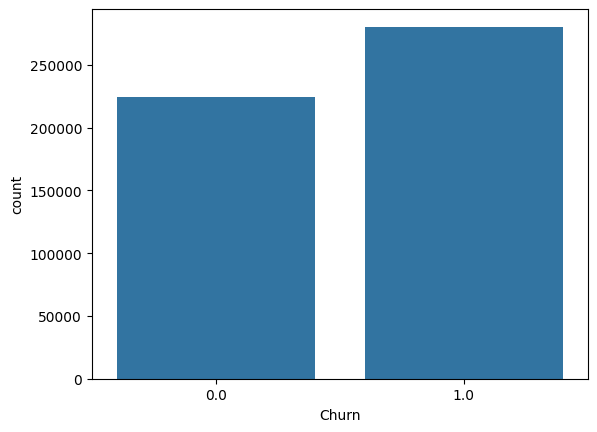

In [16]:
sns.countplot(x='Churn', data=df)
plt.show()

Exploratory Data Analysis — EDA

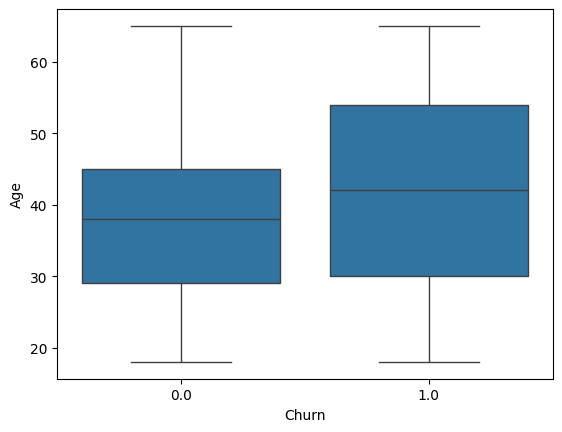

In [17]:
sns.boxplot(x='Churn', y='Age', data=df)
plt.show()

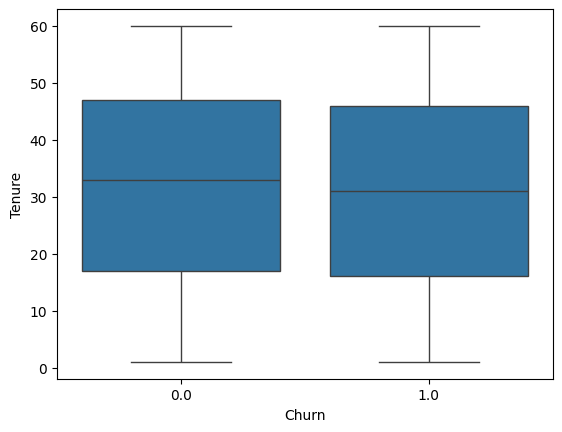

In [18]:
sns.boxplot(x='Churn', y='Tenure', data=df)
plt.show()

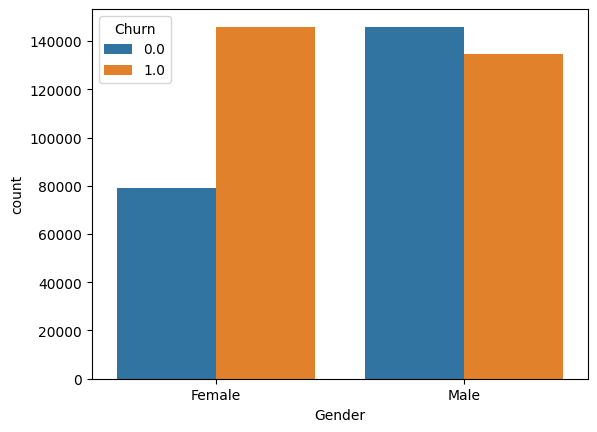

In [19]:
sns.countplot(x='Gender', hue='Churn', data=df)
plt.show()

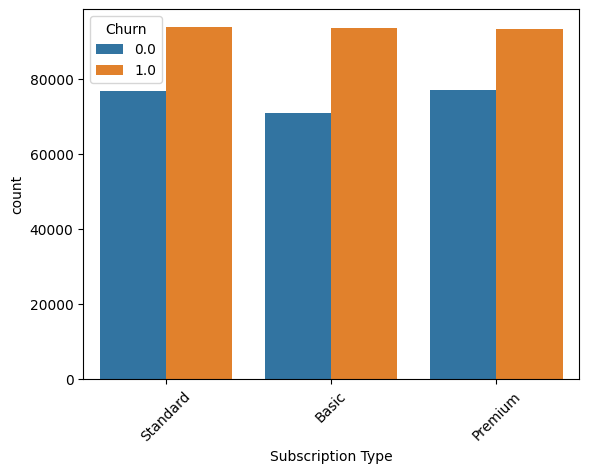

In [20]:
sns.countplot(x='Subscription Type', hue='Churn', data=df)
plt.xticks(rotation=45)
plt.show()

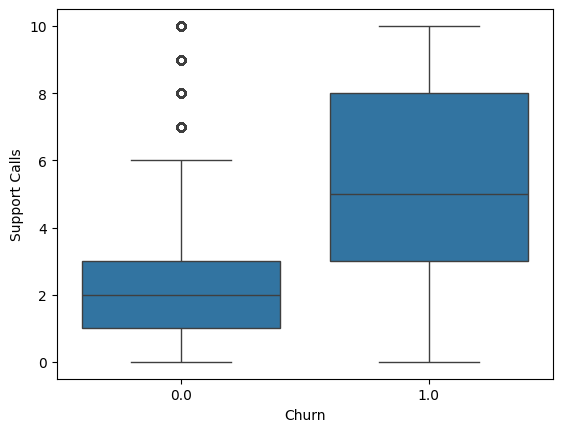

In [21]:
sns.boxplot(x='Churn', y='Support Calls', data=df)
plt.show()

In [22]:
Q1 = df['Support Calls'].quantile(0.25)
Q3 = df['Support Calls'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Handle outliers
df['Support Calls'] = df['Support Calls'].clip(lower, upper)

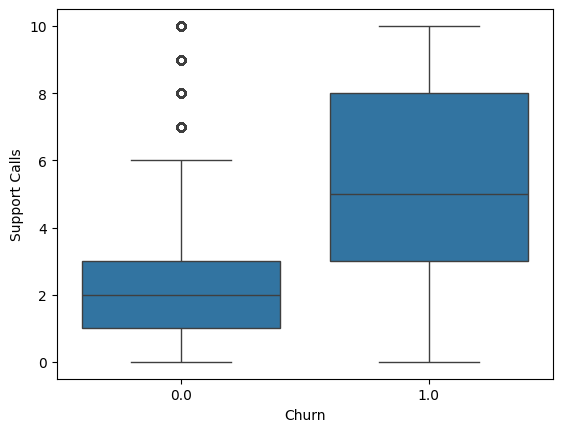

In [23]:
sns.boxplot(x='Churn', y='Support Calls', data=df)
plt.show()

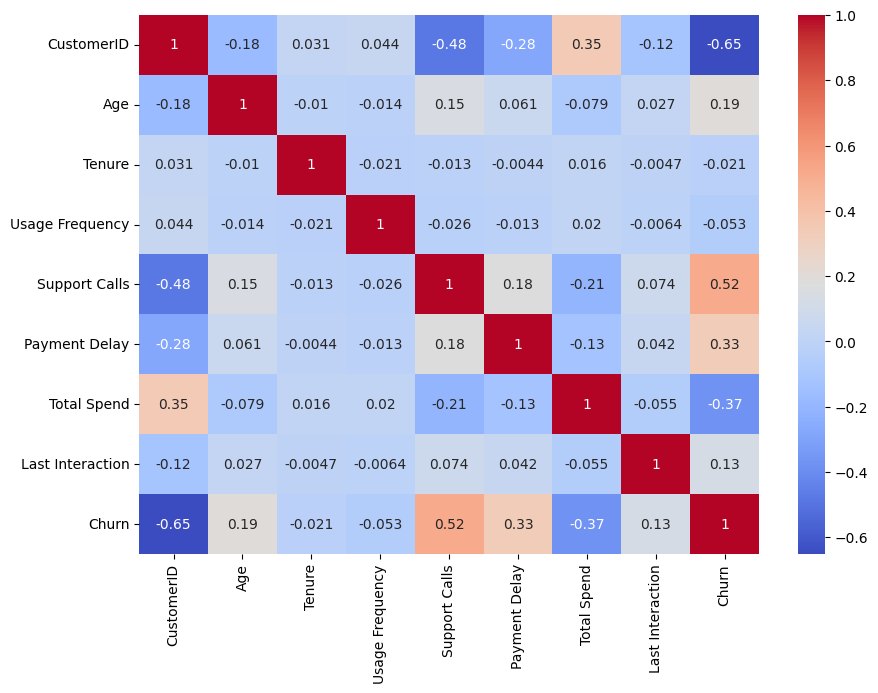

In [24]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [25]:
df = df.drop('CustomerID', axis=1)

In [26]:
df

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
505202,45.0,Female,33.0,12.0,6.0,21.0,Basic,Quarterly,947.0,14.0,1.0
505203,37.0,Male,6.0,1.0,5.0,22.0,Standard,Annual,923.0,9.0,1.0
505204,25.0,Male,39.0,14.0,8.0,30.0,Premium,Monthly,327.0,20.0,1.0
505205,50.0,Female,18.0,19.0,7.0,22.0,Standard,Monthly,540.0,13.0,1.0


In [27]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [28]:
from sklearn.preprocessing import OneHotEncoder

In [29]:
cat_cols = ["Gender","Subscription Type","Contract Length"]
X = pd.get_dummies(
    X,
    columns=cat_cols,
    drop_first=True
)

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [33]:
LR = LogisticRegression(random_state=42)
GNB = GaussianNB()
MNB = MultinomialNB()
BNB = BernoulliNB()
DTC = DecisionTreeClassifier(random_state=42,max_depth=6)
RFC = RandomForestClassifier(random_state=42,n_estimators=50)
ETC = ExtraTreesClassifier(random_state=42,n_estimators=50)
GBC = GradientBoostingClassifier(random_state=42,n_estimators=50)
BC = BaggingClassifier(random_state=42,n_estimators=50)
ABC = AdaBoostClassifier(random_state=42,n_estimators=50)
SVCM = SVC(random_state=42,kernel="sigmoid")
KNC = KNeighborsClassifier()
MLPC = MLPClassifier(random_state=42)
XGBC = XGBClassifier(random_state=42,n_estimators=50)
LGBMC = LGBMClassifier(random_state=42,n_estimators=50)

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


In [35]:
models = {
    "LR": LR,
    "GNB": GNB,
    # "MNB": MNB,
    "BNB": BNB,
    "DTC": DTC,
    "RFC": RFC,
    "ETC": ETC,
    "GBC": GBC,
    "BC": BC,
    "ABC": ABC,
    # # "SVCM": SVC,
    "KNC": KNC,
    "MLPC": MLPC,
    "XGBC": XGBC,
    "LGBMC": LGBMC
}

In [36]:
def trainClassifier(model, x_train, y_train, x_test, y_test):
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    return accuracy, precision, recall, f1, cm

In [37]:
accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
cm_scores = []
for name, model in models.items():
    accuracy, precision, recall, f1, cm = trainClassifier(
        model,
        X_train_scaled,
        y_train,
        X_test_scaled,
        y_test
    )
    print(name,"curr_accuracy",accuracy,precision,recall,f1,cm)

    accuracy_scores.append(accuracy)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)
    cm_scores.append(cm)

LR curr_accuracy 0.8495335242343067 0.8753472434681515 0.8500380282359652 0.8625070087964163 [[57228 10186]
 [12619 71529]]
GNB curr_accuracy 0.856982620973595 0.9059997920349381 0.8283500499120597 0.8654366665838941 [[60182  7232]
 [14444 69704]]
BNB curr_accuracy 0.815765165410855 0.8357959364063116 0.8315349146741455 0.8336599808181477 [[53667 13747]
 [14176 69972]]
DTC curr_accuracy 0.9203626238766973 0.8988291538478564 0.9652041640918382 0.9308349091742594 [[58272  9142]
 [ 2928 81220]]
RFC curr_accuracy 0.9361119541837664 0.8983576739956133 0.9978252602557399 0.9454825941794801 [[57914  9500]
 [  183 83965]]
ETC curr_accuracy 0.9270529552262441 0.8990435010482181 0.9784902790321814 0.9370860173445928 [[58168  9246]
 [ 1810 82338]]
GBC curr_accuracy 0.919339940090524 0.8958468634077075 0.967164995008794 0.930140861167462 [[57952  9462]
 [ 2763 81385]]
BC curr_accuracy 0.9362307174621607 0.8983942917660651 0.9980154014355659 0.9455882270150371 [[57916  9498]
 [  167 83981]]
ABC cur

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBMC curr_accuracy 0.9363362848207334 0.8982753643332941 0.9983956837952179 0.9456929787533418 [[57900  9514]
 [  135 84013]]


In [38]:
perform = {
    "Model": list(models.keys()),
    "Accuracy": accuracy_scores,
    "Precision": precision_scores,
    "recall_scores": recall_scores,
    "f1_scores": f1_scores,
}
performance_model = pd.DataFrame(perform)

In [39]:
performance_model

,Model,Accuracy,Precision,recall_scores,f1_scores
0,LR,0.849534,0.875347,0.850038,0.862507
1,GNB,0.856983,0.906000,0.828350,0.865437
2,BNB,0.815765,0.835796,0.831535,0.833660
3,DTC,0.920363,0.898829,0.965204,0.930835
4,RFC,0.936112,0.898358,0.997825,0.945483
5,ETC,0.927053,0.899044,0.978490,0.937086
6,GBC,0.919340,0.895847,0.967165,0.930141
7,BC,0.936231,0.898394,0.998015,0.945588
8,ABC,0.864669,0.903711,0.846437,0.874137
9,KNC,0.898583,0.900878,0.918382,0.909546


In [40]:
ETC = ExtraTreesClassifier(random_state=42,n_estimators=50)

In [41]:
accuracy, precision, recall, f1, cm = trainClassifier(
        ETC,
        X_train_scaled,
        y_train,
        X_test_scaled,
        y_test
    )
print("curr_accuracy",accuracy,precision,recall,f1,cm)

curr_accuracy 0.9270529552262441 0.8990435010482181 0.9784902790321814 0.9370860173445928 [[58168  9246]
 [ 1810 82338]]


In [42]:
# ETC	0.934878	0.913197	0.975424	0.943286

In [43]:
import pickle

In [47]:
with open("customer_churn_LGBMC.pkl", "wb") as file:
    pickle.dump(LGBMC, file)
# with open("scaler.pkl", "wb") as file:
#     pickle.dump(scaler, file)

In [45]:
scaler

StandardScaler()